In [4]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [5]:
train_data = pd.read_csv("train.csv")
test_data = pd.read_csv("test.csv")

print("Training Data:", train_data.shape)
print("Testing Data:", test_data.shape)

Training Data: (50000, 3073)
Testing Data: (10000, 3072)


In [6]:
print("Missing values:", train_data.isnull().sum().sum())

# Remove rows having missing labels
train_data = train_data.dropna(subset=['label'])

# Remove rows having missing pixel values
train_data = train_data.dropna()

print("Training Data after cleaning:", train_data.shape)

Missing values: 0
Training Data after cleaning: (50000, 3073)


In [7]:
# Separate input pixels and output labels
X = train_data.drop("label", axis=1)
Y = train_data["label"].astype(int)

# Testing data contains only pixel values
X_test = test_data

print("Features:", X.shape)
print("Labels:", Y.shape)

print("Classes:", sorted(Y.unique()))

Features: (50000, 3072)
Labels: (50000,)
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [8]:
X = X.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [11]:
# Split training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training samples:", X_train.shape)
print("Validation samples:", X_val.shape)

Training samples: (40000, 3072)
Validation samples: (10000, 3072)


In [31]:
model = Sequential([
    Flatten(input_shape=(3072,)),

    Dense(512, activation='relu'),
    Dropout(0.3),

    Dense(256, activation='relu'),
    Dropout(0.2),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [32]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
# Display model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 57ms/step - accuracy: 0.2417 - loss: 2.0386 - val_accuracy: 0.3347 - val_loss: 1.8560
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.3071 - loss: 1.8906 - val_accuracy: 0.3639 - val_loss: 1.7874
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.3323 - loss: 1.8326 - val_accuracy: 0.3669 - val_loss: 1.7715
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.3373 - loss: 1.8095 - val_accuracy: 0.3844 - val_loss: 1.7409
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.3477 - loss: 1.7823 - val_accuracy: 0.4030 - val_loss: 1.6895
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - accuracy: 0.3654 - loss: 1.7493 - val_accuracy: 0.4051 - val_loss: 1.6791
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.3712 - loss: 1.7343 - val_accuracy: 0.4028 - val_loss: 1.6865
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.3765 - loss: 1.7138 - 

In [35]:
# Evaluate the model
loss, accuracy = model.evaluate(X_val, y_val)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4243 - loss: 1.6412
Validation Loss: 1.6411854028701782
Validation Accuracy: 0.4242999851703644


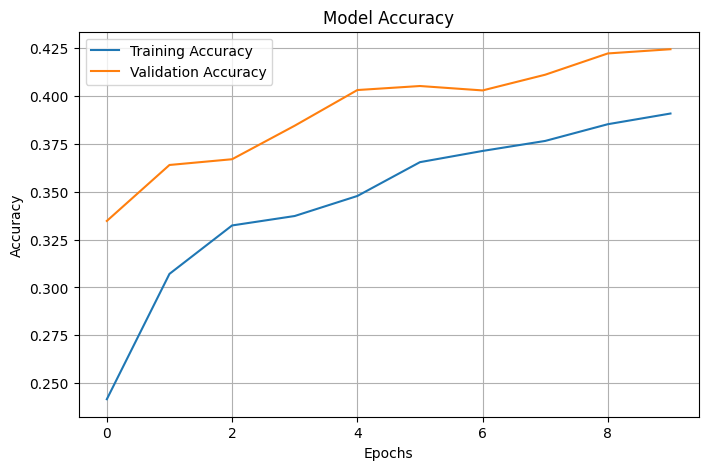

In [36]:
# Model accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

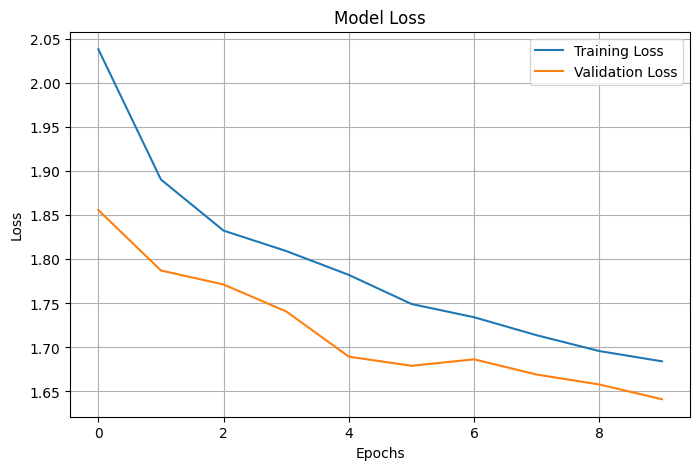

In [37]:
# Model loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


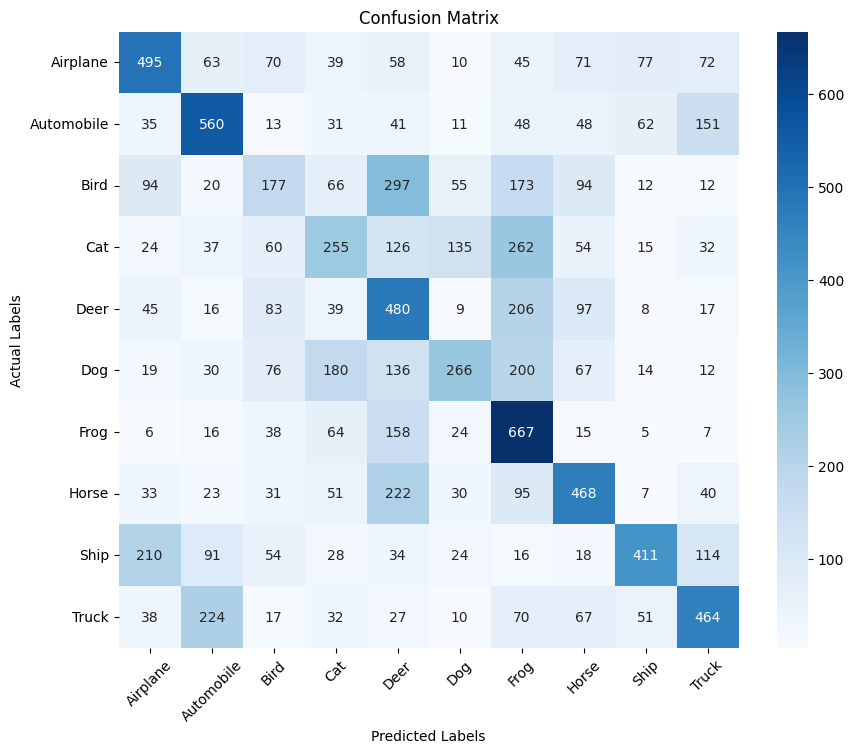

In [38]:
# Confusion matrix
# Predict validation images
predictions = model.predict(X_val)

predicted_labels = np.argmax(predictions, axis=1)

# CIFAR-10 class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Generate confusion matrix
cm = confusion_matrix(y_val, predicted_labels)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

Random Index: 2483
Predicted Label: 6
Predicted Class: Frog


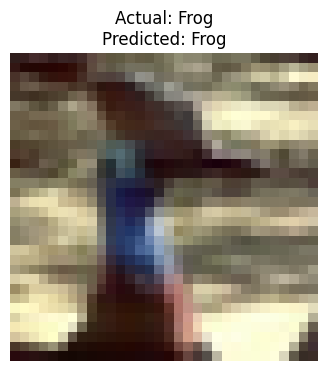

In [44]:
# Predict a random test image

# Select a random image
random_index = np.random.randint(0, len(X_test))

# Get random image
random_image = X_test.iloc[random_index]

# Predict image
prediction = model.predict(
    random_image.values.reshape(1, 3072),
    verbose=0
)

predicted_label = np.argmax(prediction)

# Print prediction
print("Random Index:", random_index)
print("Predicted Label:", predicted_label)
print("Predicted Class:", class_names[predicted_label])

# Display image
image = random_image.values.reshape(3, 32, 32).transpose(1, 2, 0)

plt.figure(figsize=(4, 4))

plt.imshow(image)
actual_label = y_val.iloc[random_index]

plt.title("Actual: " + class_names[actual_label] +
          "\nPredicted: " + class_names[predicted_label])
plt.axis('off')

plt.show()